<a href="https://colab.research.google.com/github/IltenLima/Projetos/blob/main/Projeto_11_An%C3%A1lise_da_Curva_de_Carga_Hor%C3%A1ria_do_ONS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
## Análise da Curva de Carga Horária do ONS
#Ingestão, o tratamento de valores inválidos e a análise exploratória dos dados de carga
#do Sistema Interligado Nacional (SIN).

# Importação de Bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual para os gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelpad'] = 10

In [ ]:
#Carregamento dos Dados

# Os arquivos do ONS costumam usar ponto e vírgula como separador e vírgula para decimais.
# 'din_instante' é a coluna padrão de data/hora do ONS.
caminho_arquivo = '/content/CURVA_CARGA_2025.csv' # Caminho correto do arquivo no ambiente

try:
    df_carga = pd.read_csv(
        caminho_arquivo,
        sep=';',
        decimal=',',
        parse_dates=['din_instante']
    )
    print("Dados carregados com sucesso! Linhas e Colunas:", df_carga.shape)
    # Inspecionando as primeiras linhas apenas se o carregamento for bem-sucedido
    display(df_carga.head())
except FileNotFoundError:
    print(f"Erro: O arquivo '{caminho_arquivo}' não foi encontrado. Por favor, faça o upload do arquivo para o Colab ou ajuste o caminho correto.")

Dados carregados com sucesso! Linhas e Colunas: (35040, 4)


,id_subsistema,nom_subsistema,din_instante,val_cargaenergiahomwmed
0,N,NORTE,2025-01-01 00:00:00,7097.75099999
1,NE,NORDESTE,2025-01-01 00:00:00,12251.182
2,S,SUL,2025-01-01 00:00:00,10554.60299999
3,SE,SUDESTE,2025-01-01 00:00:00,35374.03299999
4,N,NORTE,2025-01-01 01:00:00,7053.337


In [ ]:
# Identificação e Tratamento de Valores Inválidos

if 'df_carga' in globals():
    print("--- Verificando Valores Nulos ---")
    display(df_carga.isnull().sum())

    coluna_carga = 'val_cargaenergiahomwmed'

    # Garante que a coluna de carga seja interpretada como numérica
    if coluna_carga in df_carga.columns:
        df_carga[coluna_carga] = pd.to_numeric(df_carga[coluna_carga], errors='coerce')

    # 1. Tratamento de strings vazias ou espaços em branco em colunas de texto
    colunas_texto = ['nom_subsistema']
    for col in colunas_texto:
        if col in df_carga.columns:
            # Substitui strings compostas apenas por espaços por NaN
            df_carga[col] = df_carga[col].replace(r'^\s*$', np.nan, regex=True)

    # 2. Tratamento de inconsistências numéricas (Ex: Carga não pode ser negativa no ONS)
    if coluna_carga in df_carga.columns:
        registros_invalidos = df_carga[df_carga[coluna_carga] < 0].shape[0]
        print(f"\nEncontrados {registros_invalidos} registros com carga negativa (inválidos).")

        # Substituindo cargas negativas por NaN para posterior tratamento
        df_carga.loc[df_carga[coluna_carga] < 0, coluna_carga] = np.nan

    # 3. Preenchimento de dados faltantes (Imputação)
    # Como é uma série temporal, podemos usar interpolação linear ou preencher com a média do subsistema
    if coluna_carga in df_carga.columns and 'nom_subsistema' in df_carga.columns:
        df_carga[coluna_carga] = df_carga.groupby('nom_subsistema')[coluna_carga].transform(
            lambda x: x.interpolate(method='linear', limit_direction='both')
        )

    print("\n--- Verificação após imputação ---")
    display(df_carga.isnull().sum())
else:
    print("Aviso: O DataFrame 'df_carga' não foi encontrado. Por favor, certifique-se de carregar os dados com sucesso na célula anterior antes de rodar esta etapa.")

--- Verificando Valores Nulos ---


,0
id_subsistema,0
nom_subsistema,0
din_instante,0
val_cargaenergiahomwmed,0



Encontrados 0 registros com carga negativa (inválidos).

--- Verificação após imputação ---


,0
id_subsistema,0
nom_subsistema,0
din_instante,0
val_cargaenergiahomwmed,0


In [ ]:
# Remoção de Duplicatas

# Verificando se há instantes duplicados para o mesmo subsistema
duplicatas = df_carga.duplicated(subset=['din_instante', 'nom_subsistema'], keep=False)
print(f"Total de registros duplicados exatos encontrados: {duplicatas.sum()}")

# Mantendo apenas o último registro em caso de duplicata de horário/subsistema
df_carga = df_carga.drop_duplicates(subset=['din_instante', 'nom_subsistema'], keep='last')

# Garantindo que os dados estejam ordenados cronologicamente
df_carga = df_carga.sort_values(by=['nom_subsistema', 'din_instante']).reset_index(drop=True)

Total de registros duplicados exatos encontrados: 0


In [ ]:
# Análise Exploratória e Agrupamento

# Definição do nome correto da coluna de carga
coluna_carga = 'val_cargaenergiahomwmed'

# Qual a carga média por subsistema (Sul, Sudeste/ Centro-Oeste, Nordeste, Norte)?
carga_media_subsistema = df_carga.groupby('nom_subsistema')[coluna_carga].mean().reset_index()
carga_media_subsistema = carga_media_subsistema.sort_values(by=coluna_carga, ascending=False)

display(carga_media_subsistema)

# Criando colunas de Mês e Hora para análise de sazonalidade
df_carga['mes'] = df_carga['din_instante'].dt.month
df_carga['hora'] = df_carga['din_instante'].dt.hour

,nom_subsistema,val_cargaenergiahomwmed
2,SUDESTE,44225.909113
3,SUL,13804.431484
0,NORDESTE,13266.864794
1,NORTE,8311.701382


In [ ]:
# Cálculo da Carga Média Mensal por Subsistema

coluna_carga = 'val_cargaenergiahomwmed'

# Agrupando por subsistema e mês, calculando a média
carga_media_mensal = df_carga.groupby(['nom_subsistema', 'mes'])[coluna_carga].mean().reset_index()

# Ordenando para facilitar a leitura
carga_media_mensal = carga_media_mensal.sort_values(by=['nom_subsistema', 'mes'])

# Pivotando a tabela para uma visualização em formato de matriz (Meses nas colunas)
carga_mensal_pivot = carga_media_mensal.pivot(index='nom_subsistema', columns='mes', values=coluna_carga)

print("--- Carga Média Mensal por Subsistema (MWmed) ---")
display(carga_mensal_pivot)

--- Carga Média Mensal por Subsistema (MWmed) ---


mes,1,2,3,4,5,6,7,8,9,10,11,12
nom_subsistema,,,,,,,,,,,,
NORDESTE,13413.739379,13739.950530,13792.189364,13829.252121,13322.290313,12762.132685,12209.762642,12449.615200,13036.568203,13318.657934,13814.669012,13571.434660
NORTE,7636.911808,7705.452859,7945.508030,8099.944351,8147.798237,8095.044475,8168.313710,8616.179337,8931.424349,8952.695390,8971.999921,8437.946116
SUDESTE,46753.531530,51068.716030,48586.325054,44297.410269,41856.359319,41058.529589,40356.674718,41177.329304,42854.220921,43616.251810,43903.619653,45689.636798
SUL,15296.750024,16692.659525,15648.576801,13165.044878,12914.781026,12704.481897,13400.596585,12499.434440,12596.212222,12805.386183,13486.569624,14616.854503


In [ ]:
# Mapeamento para incluir o Centro-Oeste explicitamente junto ao Sudeste
renomear_subsistema = {'SUDESTE': 'SUDESTE/CENTRO-OESTE'}

# Atualizando o DataFrame de carga média por subsistema
carga_media_subsistema_co = carga_media_subsistema.copy()
carga_media_subsistema_co['nom_subsistema'] = carga_media_subsistema_co['nom_subsistema'].replace(renomear_subsistema)

# Atualizando a tabela dinâmica mensal (index/linhas)
carga_mensal_pivot_co = carga_mensal_pivot.rename(index=renomear_subsistema)

# Exibindo os resultados atualizados
print("--- Carga Média por Subsistema com Centro-Oeste (MWmed) ---")
display(carga_media_subsistema_co)

print("\n--- Carga Média Mensal por Subsistema com Centro-Oeste (MWmed) ---")
display(carga_mensal_pivot_co)

--- Carga Média por Subsistema com Centro-Oeste (MWmed) ---


,nom_subsistema,val_cargaenergiahomwmed
2,SUDESTE/CENTRO-OESTE,44225.909113
3,SUL,13804.431484
0,NORDESTE,13266.864794
1,NORTE,8311.701382



--- Carga Média Mensal por Subsistema com Centro-Oeste (MWmed) ---


mes,1,2,3,4,5,6,7,8,9,10,11,12
nom_subsistema,,,,,,,,,,,,
NORDESTE,13413.739379,13739.950530,13792.189364,13829.252121,13322.290313,12762.132685,12209.762642,12449.615200,13036.568203,13318.657934,13814.669012,13571.434660
NORTE,7636.911808,7705.452859,7945.508030,8099.944351,8147.798237,8095.044475,8168.313710,8616.179337,8931.424349,8952.695390,8971.999921,8437.946116
SUDESTE/CENTRO-OESTE,46753.531530,51068.716030,48586.325054,44297.410269,41856.359319,41058.529589,40356.674718,41177.329304,42854.220921,43616.251810,43903.619653,45689.636798
SUL,15296.750024,16692.659525,15648.576801,13165.044878,12914.781026,12704.481897,13400.596585,12499.434440,12596.212222,12805.386183,13486.569624,14616.854503


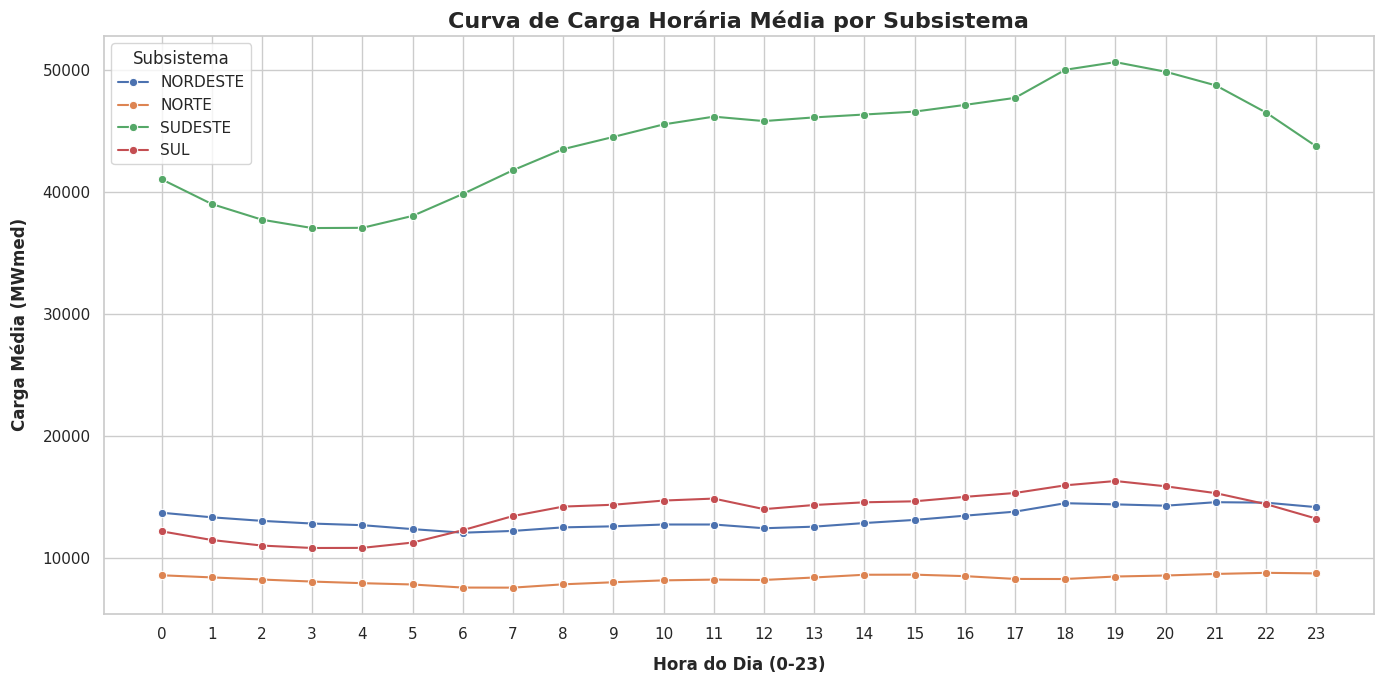

In [ ]:
# Visualização da Curva de Carga Diária

# Definição do nome correto da coluna de carga
coluna_carga = 'val_cargaenergiahomwmed'

# Calculando a curva de carga média por hora do dia para cada subsistema
curva_diaria = df_carga.groupby(['hora', 'nom_subsistema'])[coluna_carga].mean().reset_index()

# Plotando a Curva de Carga
plt.figure(figsize=(14, 7))
sns.lineplot(data=curva_diaria, x='hora', y=coluna_carga, hue='nom_subsistema', marker='o')

plt.title('Curva de Carga Horária Média por Subsistema', fontsize=16)
plt.xlabel('Hora do Dia (0-23)', fontsize=12)
plt.ylabel('Carga Média (MWmed)', fontsize=12)
plt.xticks(range(0, 24))
plt.legend(title='Subsistema')
plt.tight_layout()
plt.show()

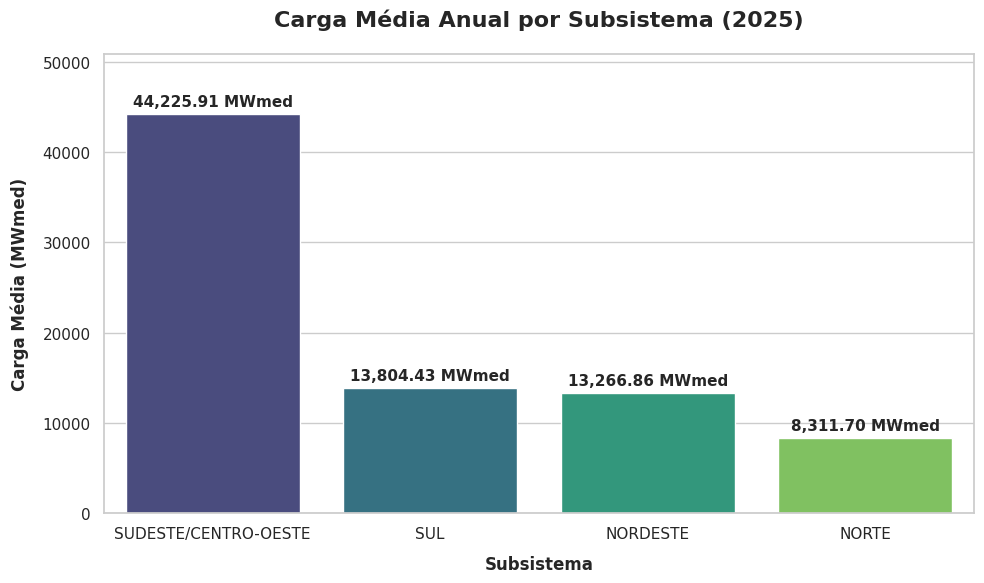

In [ ]:
# Gráfico de Barras: Comparativo de Carga Média Anual por Subsistema

plt.figure(figsize=(10, 6))

# Criando o gráfico de barras usando os dados atualizados com o Centro-Oeste
ax = sns.barplot(
    data=carga_media_subsistema_co,
    x='nom_subsistema',
    y='val_cargaenergiahomwmed',
    hue='nom_subsistema',
    palette='viridis',
    legend=False
)

# Adicionando rótulos com os valores em cima de cada barra para facilitar a leitura
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():,.2f} MWmed",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center',
        va='center',
        xytext=(0, 9),
        textcoords='offset points',
        fontsize=11,
        weight='bold'
    )

plt.title('Carga Média Anual por Subsistema (2025)', fontsize=16, pad=20)
plt.xlabel('Subsistema', fontsize=12)
plt.ylabel('Carga Média (MWmed)', fontsize=12)
plt.ylim(0, carga_media_subsistema_co['val_cargaenergiahomwmed'].max() * 1.15) # Espaço para o rótulo

plt.tight_layout()
plt.show()

In [ ]:
# Cálculo da variação percentual entre pico e vale de carga por subsistema

# Criando um dicionário para armazenar as análises
analise_sazonalidade = []

for subsistema in carga_mensal_pivot_co.index:
    serie_mensal = carga_mensal_pivot_co.loc[subsistema]

    # Identificando pico (máximo) e vale (mínimo)
    mes_pico = serie_mensal.idxmax()
    val_pico = serie_mensal.max()

    mes_vale = serie_mensal.idxmin()
    val_vale = serie_mensal.min()

    # Cálculo da variação percentual
    variacao_pct = ((val_pico - val_vale) / val_vale) * 100

    analise_sazonalidade.append({
        'Subsistema': subsistema,
        'Mês de Vale': mes_vale,
        'Carga Vale (MWmed)': val_vale,
        'Mês de Pico': mes_pico,
        'Carga Pico (MWmed)': val_pico,
        'Variação (%)': variacao_pct
    })

# Convertendo para DataFrame para melhor visualização
df_sazonalidade = pd.DataFrame(analise_sazonalidade)

print("--- Variação Sazonal (Pico vs Vale) por Subsistema em 2025 ---")
display(df_sazonalidade.style.format({
    'Carga Vale (MWmed)': '{:,.2f}',
    'Carga Pico (MWmed)': '{:,.2f}',
    'Variação (%)': '{:,.2f}%'
}))

--- Variação Sazonal (Pico vs Vale) por Subsistema em 2025 ---


,Subsistema,Mês de Vale,Carga Vale (MWmed),Mês de Pico,Carga Pico (MWmed),Variação (%)
0,NORDESTE,7,"12,209.76",4,"13,829.25",13.26%
1,NORTE,1,"7,636.91",11,"8,972.00",17.48%
2,SUDESTE/CENTRO-OESTE,7,"40,356.67",2,"51,068.72",26.54%
3,SUL,8,"12,499.43",2,"16,692.66",33.55%


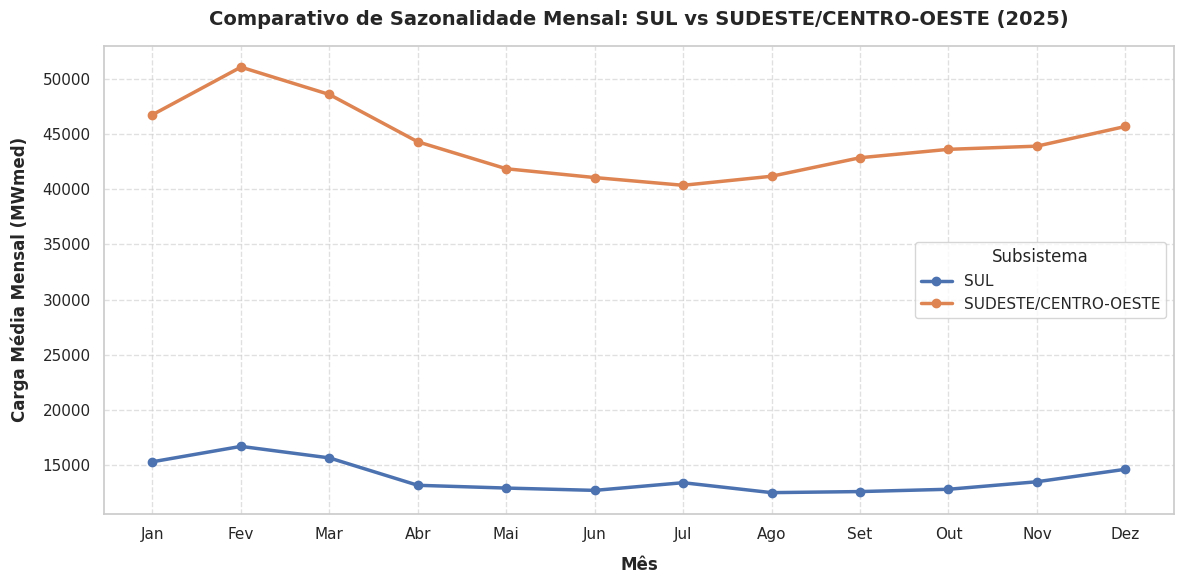

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrando os dados mensais especificamente para Sul e Sudeste/Centro-Oeste
subsistemas_selecionados = ['SUL', 'SUDESTE/CENTRO-OESTE']
df_filtrado = carga_mensal_pivot_co.loc[subsistemas_selecionados].T

# Plotando o gráfico de linhas para analisar a sazonalidade
plt.figure(figsize=(12, 6))
for col in df_filtrado.columns:
    plt.plot(df_filtrado.index, df_filtrado[col], marker='o', linewidth=2.5, label=col)

plt.title('Comparativo de Sazonalidade Mensal: SUL vs SUDESTE/CENTRO-OESTE (2025)', fontsize=14, pad=15)
plt.xlabel('Mês', fontsize=12)
plt.ylabel('Carga Média Mensal (MWmed)', fontsize=12)
plt.xticks(range(1, 13), ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Subsistema', fontsize=11)
plt.tight_layout()
plt.show()

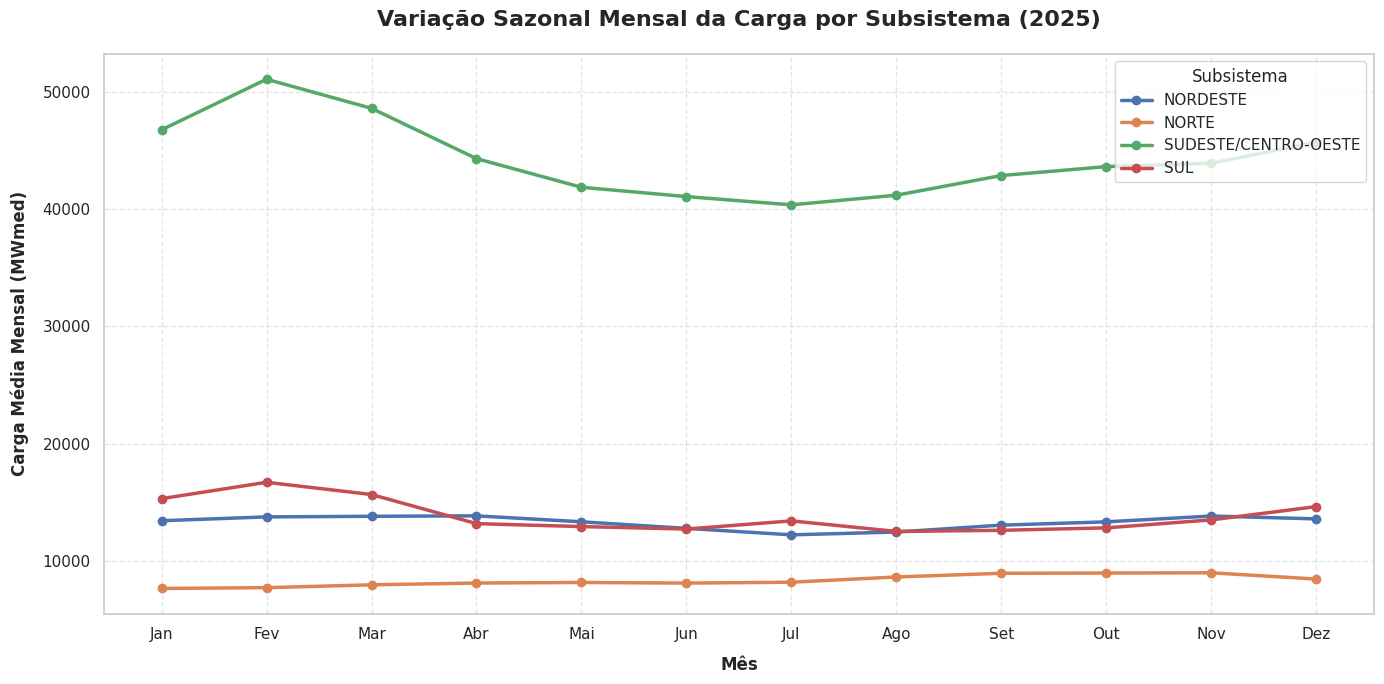

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Transpondo a tabela dinâmica de todos os subsistemas com Centro-Oeste integrado
df_todos_subsistemas = carga_mensal_pivot_co.T

# Criando o gráfico de linhas para todos os subsistemas
plt.figure(figsize=(14, 7))
for col in df_todos_subsistemas.columns:
    plt.plot(
        df_todos_subsistemas.index,
        df_todos_subsistemas[col],
        marker='o',
        linewidth=2.5,
        label=col
    )

plt.title('Variação Sazonal Mensal da Carga por Subsistema (2025)', fontsize=16, pad=20)
plt.xlabel('Mês', fontsize=12)
plt.ylabel('Carga Média Mensal (MWmed)', fontsize=12)
plt.xticks(range(1, 13), ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Subsistema', fontsize=11, loc='upper right')
plt.tight_layout()
plt.show()

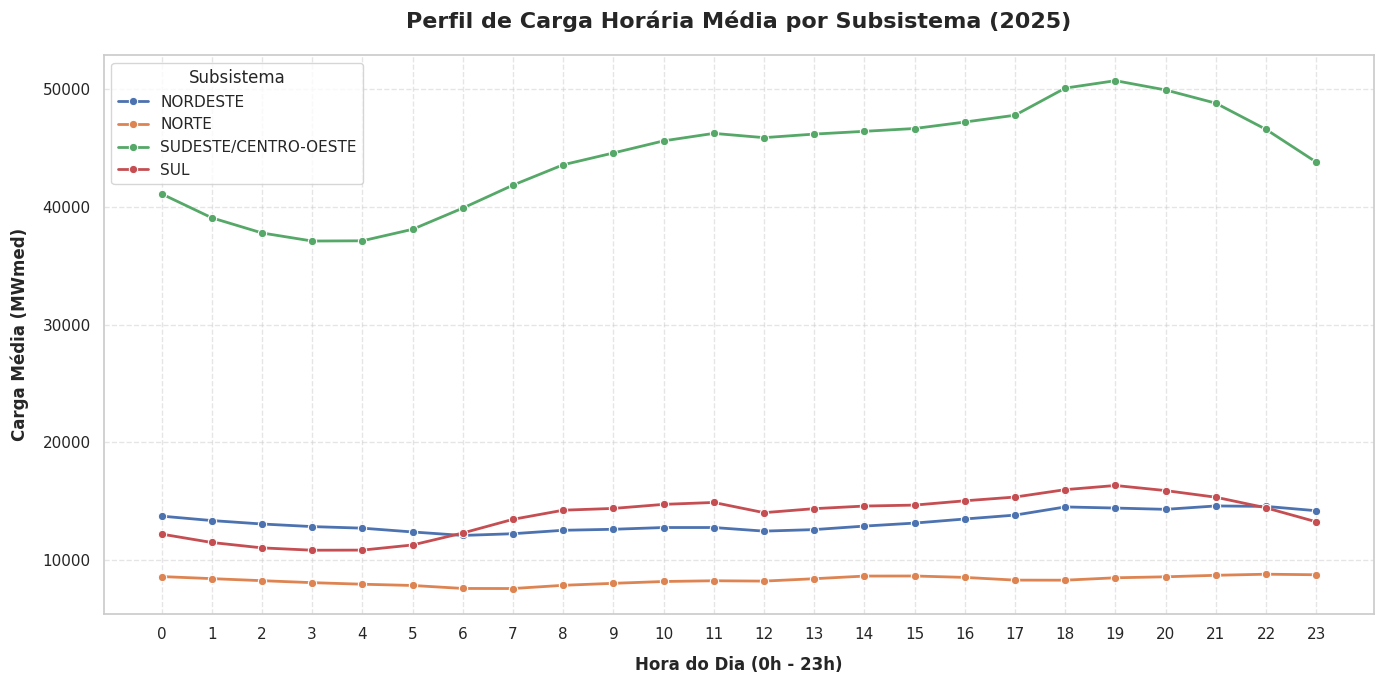

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Criando uma cópia do dataframe de carga para aplicar o mapeamento do Centro-Oeste
df_carga_co = df_carga.copy()
renomear_subsistema = {'SUDESTE': 'SUDESTE/CENTRO-OESTE'}
df_carga_co['nom_subsistema'] = df_carga_co['nom_subsistema'].replace(renomear_subsistema)

# Calculando a curva de carga média por hora do dia para cada subsistema
coluna_carga = 'val_cargaenergiahomwmed'
curva_diaria_co = df_carga_co.groupby(['hora', 'nom_subsistema'])[coluna_carga].mean().reset_index()

# Plotando a Curva de Carga Horária
plt.figure(figsize=(14, 7))
sns.lineplot(data=curva_diaria_co, x='hora', y=coluna_carga, hue='nom_subsistema', marker='o', linewidth=2)

plt.title('Perfil de Carga Horária Média por Subsistema (2025)', fontsize=16, pad=20)
plt.xlabel('Hora do Dia (0h - 23h)', fontsize=12)
plt.ylabel('Carga Média (MWmed)', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Subsistema', fontsize=11)
plt.tight_layout()
plt.show()